--- РАБОТА 1: Анализ данных IQ ---

Описательная статистика:
                  Среднее: 111.1600
       Стандартная ошибка: 1.7329
                  Медиана: 108.0000
                     Мода: 105
   Стандартное отклонение: 15.0072
        Дисперсия выборки: 225.2173
                  Эксцесс: -0.3454
          Асимметричность: 0.4981
                 Интервал: 65
                  Минимум: 83
                 Максимум: 148
                    Сумма: 8337
                     Счет: 75
Уровень надежности(95.0%): 3.3964

Таблица частот:
Bin
83          1
91,125      4
99,25      10
107,375    22
115,5      14
123,625     7
131,75      8
139,875     6
Еще         3
Name: count, dtype: int64


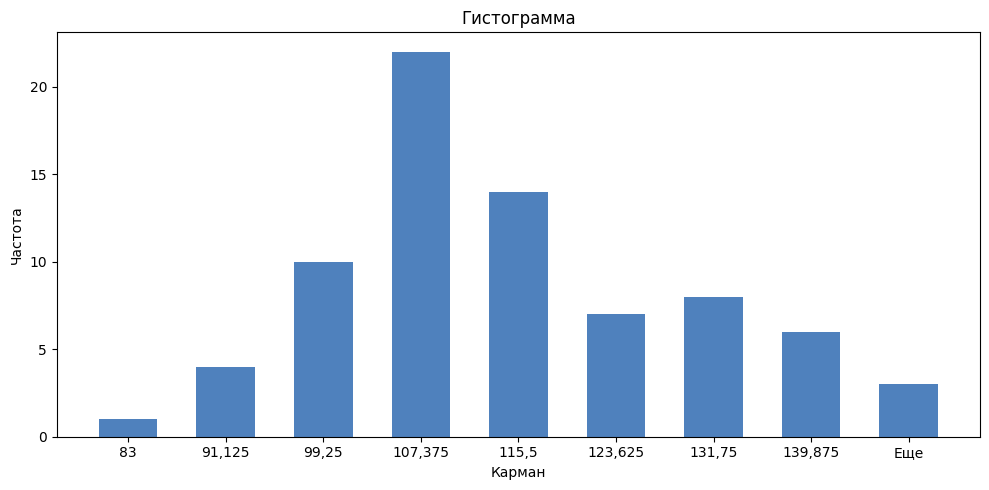

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, chi2, chisquare

# ==========================================
# РАБОТА 1: Описательная статистика и гистограмма
# ==========================================

print("--- РАБОТА 1: Анализ данных IQ ---\n")

# 1. Ввод данных (75 значений из Слайда 5)
iq_data = [
    141, 104, 101, 130, 148, 92, 87, 115, 91, 96,
    100, 133, 124, 92, 123, 132, 118, 98, 101, 107,
    97, 124, 118, 146, 107, 110, 111, 138, 121, 129,
    106, 135, 97, 108, 108, 107, 110, 101, 129, 105,
    105, 110, 116, 113, 123, 83, 127, 112, 114, 105,
    127, 114, 113, 106, 139, 95, 105, 95, 105, 106,
    109, 102, 102, 102, 89, 108, 92, 131, 86, 134,
    104, 94, 121, 107, 103
]

df_iq = pd.DataFrame(iq_data, columns=['IQ'])

# 2. Расчет описательной статистики (как в Excel)
stats = {
    'Среднее': df_iq['IQ'].mean(),
    'Стандартная ошибка': df_iq['IQ'].sem(),
    'Медиана': df_iq['IQ'].median(),
    'Мода': df_iq['IQ'].mode()[0],
    'Стандартное отклонение': df_iq['IQ'].std(),
    'Дисперсия выборки': df_iq['IQ'].var(),
    'Эксцесс': df_iq['IQ'].kurt(),
    'Асимметричность': df_iq['IQ'].skew(),
    'Интервал': df_iq['IQ'].max() - df_iq['IQ'].min(),
    'Минимум': df_iq['IQ'].min(),
    'Максимум': df_iq['IQ'].max(),
    'Сумма': df_iq['IQ'].sum(),
    'Счет': df_iq['IQ'].count()
}

# Добавление уровня надежности (95.0%)
stats['Уровень надежности(95.0%)'] = stats['Стандартная ошибка'] * 1.959963984540054 

print("Описательная статистика:")
for key, value in stats.items():
    print(f"{key:>25}: {value:.4f}" if isinstance(value, float) else f"{key:>25}: {value}")

bins = [float('-inf'), 83, 91.125, 99.25, 107.375, 115.5, 123.625, 131.75, 139.875, float('inf')]
bin_labels = ['83', '91,125', '99,25', '107,375', '115,5', '123,625', '131,75', '139,875', 'Еще']

# Категоризация данных по карманам (интервалам)
df_iq['Bin'] = pd.cut(df_iq['IQ'], bins=bins, labels=bin_labels, right=True)
freq_table = df_iq['Bin'].value_counts().reindex(bin_labels)

print("\nТаблица частот:")
print(freq_table)

# Построение гистограммы
plt.figure(figsize=(10, 5))
x_pos = np.arange(len(freq_table))
plt.bar(x_pos, freq_table.values, width=0.6, color='#4f81bd', align='center')
plt.xticks(x_pos, freq_table.index)
plt.title('Гистограмма')
plt.xlabel('Карман')
plt.ylabel('Частота')
plt.tight_layout()
plt.show()

In [6]:
print("\n--- РАБОТА 2: Критерий хи-квадрат (Пирсона) ---\n")

def perform_chi_square(group_name, empirical_data):
    """
    Функция для проведения теста хи-квадрат с шагами как в Excel.
    """
    print(f"=== {group_name} ===")
    
    # 1. Создание таблицы сопряженности
    df = pd.DataFrame(empirical_data, 
                      index=['Много', 'Мало', 'Практически не покупает'], 
                      columns=['Женат/Замужем', 'Неженат/Незамужем'])
    
    # 2. Расчет итогов
    df['Итоги по строкам'] = df.sum(axis=1)
    df.loc['Итоги по столбцам'] = df.sum()
    grand_total = df.loc['Итоги по столбцам', 'Итоги по строкам']
    
    print("Таблица сопряженности (Эмпирические частоты):")
    print(df)
    
    # 3. Расчет теоретических частот
    # Формула: (Итог по строке * Итог по столбцу) / Общий итог
    expected = pd.DataFrame(index=df.index[:3], columns=df.columns[:2], dtype=float)
    for r in expected.index:
        for c in expected.columns:
            expected.loc[r, c] = (df.loc[r, 'Итоги по строкам'] * df.loc['Итоги по столбцам', c]) / grand_total
            
    print("\nТеоретические частоты:")
    print(expected.round(2))
    
    # 4. Проведение теста хи-квадрат с помощью SciPy
    empirical_only = df.iloc[:3, :2] 
    chi2_stat, p_value, dof, expected_scipy = chi2_contingency(empirical_only)
    
    # 5. Расчет критического значения (уровень значимости 95%, alpha = 0.05)
    alpha = 0.05
    critical_value = chi2.ppf(1 - alpha, dof)
    
    print("\n--- Результаты ---")
    print(f"Хи-квадрат эмпирический (Chi2): {chi2_stat:.3f}")
    print(f"Число степеней свободы (v):     {dof}")
    print(f"Критическое значение (Chi2 кр): {critical_value:.3f}")
    
    # 6. Вывод
    if chi2_stat < critical_value:
        print(f"Вывод: Так как {chi2_stat:.3f} < {critical_value:.3f}, различия статистически недостоверны.")
        print("=> Связи между семейным положением и покупками НЕТ.")
    else:
        print(f"Вывод: Так как {chi2_stat:.3f} > {critical_value:.3f}, различия статистически значимы.")
        print("=> Связь между семейным положением и покупками ЕСТЬ.")
    print("\n" + "="*40 + "\n")

# Данные (Мужчины)
men_data = [
    [32, 12], # Много
    [70, 19], # Мало
    [5, 5]    # Практически не покупает
]
perform_chi_square("МУЖЧИНЫ", men_data)

# Данные (Женщины)
women_data = [
    [24, 31], # Много
    [75, 20], # Мало
    [7, 5]    # Практически не покупает
]
perform_chi_square("ЖЕНЩИНЫ", women_data)


--- РАБОТА 2: Критерий хи-квадрат (Пирсона) ---

=== МУЖЧИНЫ ===
Таблица сопряженности (Эмпирические частоты):
                         Женат/Замужем  Неженат/Незамужем  Итоги по строкам
Много                               32                 12                44
Мало                                70                 19                89
Практически не покупает              5                  5                10
Итоги по столбцам                  107                 36               143

Теоретические частоты:
                         Женат/Замужем  Неженат/Незамужем
Много                            32.92              11.08
Мало                             66.59              22.41
Практически не покупает           7.48               2.52

--- Результаты ---
Хи-квадрат эмпирический (Chi2): 4.066
Число степеней свободы (v):     2
Критическое значение (Chi2 кр): 5.991
Вывод: Так как 4.066 < 5.991, различия статистически недостоверны.
=> Связи между семейным положением и покупками НЕТ.


=

In [4]:

# ==========================================
# ЗАДАНИЕ 1: Критерий независимости (хи-квадрат)
# ==========================================
print("--- ЗАДАНИЕ 1: Зависимость между возрастом и затратами ---\n")

# 1. Создание таблицы сопряженности (по данным из картинки)
data_task1 = {
    'Высокий': [25, 52, 12],
    'Средний': [40, 63, 23],
    'Низкий': [31, 47, 58]
}
df1 = pd.DataFrame(data_task1, index=['Молодые', 'Среднего возраста', 'Пожилые'])

# 2. Добавление итогов по строкам и столбцам
df1['Всего'] = df1.sum(axis=1)
df1.loc['Всего'] = df1.sum()
grand_total = df1.loc['Всего', 'Всего']

print("Таблица с эмпирическими частотами и итогами:")
print(df1, "\n")

# 3. Расчет теоретических частот
# Формула: (Итог по строке * Итог по столбцу) / Общий итог
expected_freq = pd.DataFrame(index=df1.index[:3], columns=df1.columns[:3], dtype=float)
for r in expected_freq.index:
    for c in expected_freq.columns:
        expected_freq.loc[r, c] = (df1.loc[r, 'Всего'] * df1.loc['Всего', c]) / grand_total

print("Теоретические (ожидаемые) частоты:")
print(expected_freq.round(2), "\n")

# 4. Вычисление критерия хи-квадрат (без поправки Йетса)
# Извлекаем только матрицу 3х3 с данными
observed_matrix = df1.iloc[:3, :3]
chi2_stat, p_value, dof, expected_scipy = chi2_contingency(observed_matrix, correction=False)

# 5. Критическое значение (уровень значимости alpha = 0.05)
alpha = 0.05
critical_value = chi2.ppf(1 - alpha, dof)

print("--- Результаты (Задание 1) ---")
print(f"Хи-квадрат эмпирический (Chi2): {chi2_stat:.3f}")
print(f"Число степеней свободы (v):     {dof}  (формула: (3-1)*(3-1))")
print(f"Критическое значение (Chi2 кр): {critical_value:.3f}")
print(f"p-value:                        {p_value:.5f}")

if chi2_stat > critical_value:
    print("\nВЫВОД: Хи2_эмп > Хи2_крит. Нулевая гипотеза отвергается.")
    print("=> Существует статистически значимая зависимость между возрастом клиента и затратами на отдых.")
else:
    print("\nВЫВОД: Хи2_эмп < Хи2_крит. Нулевая гипотеза принимается.")
    print("=> Зависимости между возрастом и затратами не обнаружено.")

--- ЗАДАНИЕ 1: Зависимость между возрастом и затратами ---

Таблица с эмпирическими частотами и итогами:
                   Высокий  Средний  Низкий  Всего
Молодые                 25       40      31     96
Среднего возраста       52       63      47    162
Пожилые                 12       23      58     93
Всего                   89      126     136    351 

Теоретические (ожидаемые) частоты:
                   Высокий  Средний  Низкий
Молодые              24.34    34.46   37.20
Среднего возраста    41.08    58.15   62.77
Пожилые              23.58    33.38   36.03 

--- Результаты (Задание 1) ---
Хи-квадрат эмпирический (Chi2): 31.518
Число степеней свободы (v):     4  (формула: (3-1)*(3-1))
Критическое значение (Chi2 кр): 9.488
p-value:                        0.00000

ВЫВОД: Хи2_эмп > Хи2_крит. Нулевая гипотеза отвергается.
=> Существует статистически значимая зависимость между возрастом клиента и затратами на отдых.


In [5]:
# ==========================================
# ЗАДАНИЕ 2: Критерий согласия (хи-квадрат)
# ==========================================
print("\n" + "="*50 + "\n")
print("--- ЗАДАНИЕ 2: Равномерность обращений по дням недели ---\n")

# 1. Данные из таблицы
days = ['Понедельник', 'Вторник', 'Среда', 'Четверг', 'Пятница', 'Суббота', 'Воскресенье']
observed_calls = np.array([9, 6, 7, 6, 9, 15, 18])
total_calls = observed_calls.sum()

# 2. Ожидаемые частоты (при равномерном распределении)
# Если бы распределение было равномерным, в каждый день было бы одинаковое число звонков
expected_uniform = np.full(len(days), total_calls / len(days))

df2 = pd.DataFrame({
    'День недели': days,
    'Эмпирическая частота': observed_calls,
    'Теоретическая частота': expected_uniform
})

print("Таблица частот:")
print(df2.to_string(index=False), "\n")

# 3. Вычисление критерия хи-квадрат согласия
chi2_stat2, p_value2 = chisquare(f_obs=observed_calls, f_exp=expected_uniform)
dof2 = len(days) - 1 # Степени свободы: k - 1 = 7 - 1 = 6

# 4. Критическое значение
critical_value2 = chi2.ppf(1 - alpha, dof2)

print("--- Результаты (Задание 2) ---")
print(f"Хи-квадрат эмпирический (Chi2): {chi2_stat2:.3f}")
print(f"Число степеней свободы (v):     {dof2}  (формула: 7-1)")
print(f"Критическое значение (Chi2 кр): {critical_value2:.3f}")
print(f"p-value:                        {p_value2:.5f}")

if chi2_stat2 > critical_value2:
    print("\nВЫВОД: Хи2_эмп > Хи2_крит. Нулевая гипотеза о равномерном распределении отвергается.")
    print("=> Частота обращений НЕРАВНОМЕРНО распределяется по дням недели (есть явные пики на выходных).")
else:
    print("\nВЫВОД: Хи2_эмп < Хи2_крит. Нулевая гипотеза принимается.")
    print("=> Распределение обращений можно считать равномерным.")



--- ЗАДАНИЕ 2: Равномерность обращений по дням недели ---

Таблица частот:
День недели  Эмпирическая частота  Теоретическая частота
Понедельник                     9                   10.0
    Вторник                     6                   10.0
      Среда                     7                   10.0
    Четверг                     6                   10.0
    Пятница                     9                   10.0
    Суббота                    15                   10.0
Воскресенье                    18                   10.0 

--- Результаты (Задание 2) ---
Хи-квадрат эмпирический (Chi2): 13.200
Число степеней свободы (v):     6  (формула: 7-1)
Критическое значение (Chi2 кр): 12.592
p-value:                        0.03997

ВЫВОД: Хи2_эмп > Хи2_крит. Нулевая гипотеза о равномерном распределении отвергается.
=> Частота обращений НЕРАВНОМЕРНО распределяется по дням недели (есть явные пики на выходных).
